In [7]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

In [8]:
import pandas as pd
import numpy as np

In [9]:
df = pd.read_csv('seeds_dataset.txt', sep='\s+', header=None)
df.columns = ['feature-1', 'feature-2', 'feature-3', 'feature-4', 'feature-5', 'feature-6', 'feature-7', 'class']
df

,feature-1,feature-2,feature-3,feature-4,feature-5,feature-6,feature-7,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


## Балансировка классов

In [11]:
df['class'].value_counts()

1    70
2    70
3    70
Name: class, dtype: int64

## Уникальные значения в столбце

In [13]:
print(df['feature-1'].nunique())
print(df['feature-2'].nunique())
print(df['feature-3'].nunique())
print(df['feature-4'].nunique())
print(df['feature-5'].nunique())
print(df['feature-6'].nunique())
print(df['feature-7'].nunique())

193
170
186
188
184
207
148


## Пустые значения
В данном датасете их нет

## Нормализация и стандратизация

In [16]:
from sklearn.preprocessing import MinMaxScaler

x = df.drop('class', axis = 1)
scaler = MinMaxScaler()
data_arr = scaler.fit_transform(x)
data = pd.DataFrame(data_arr, columns=x.columns)
data['class'] = df['class']
data

,feature-1,feature-2,feature-3,feature-4,feature-5,feature-6,feature-7,class
0,0.440982,0.502066,0.570780,0.486486,0.486101,0.189302,0.345150,1
1,0.405099,0.446281,0.662432,0.368806,0.501069,0.032883,0.215165,1
2,0.349386,0.347107,0.879310,0.220721,0.503920,0.251453,0.150665,1
3,0.306893,0.316116,0.793103,0.239302,0.533856,0.194243,0.140817,1
4,0.524079,0.533058,0.864791,0.427365,0.664291,0.076701,0.322994,1
...,...,...,...,...,...,...,...,...
205,0.151086,0.163223,0.637024,0.134009,0.250178,0.372635,0.172821,3
206,0.060434,0.097107,0.390200,0.135698,0.117605,0.462872,0.238306,3
207,0.246459,0.258264,0.727768,0.189752,0.429081,0.981667,0.264402,3
208,0.118036,0.165289,0.399274,0.155405,0.146828,0.368344,0.258493,3


In [17]:
data.min(), data.max()

(feature-1    0.0
 feature-2    0.0
 feature-3    0.0
 feature-4    0.0
 feature-5    0.0
 feature-6    0.0
 feature-7    0.0
 class        1.0
 dtype: float64,
 feature-1    1.0
 feature-2    1.0
 feature-3    1.0
 feature-4    1.0
 feature-5    1.0
 feature-6    1.0
 feature-7    1.0
 class        3.0
 dtype: float64)

## Разделение данных

In [21]:
from sklearn.model_selection import train_test_split

X = data.drop('class', axis = 1)
Y = data['class']
X.shape, Y.shape

((168, 7), (42, 7), (168,), (42,))

## KMeans

In [23]:
from sklearn.cluster import KMeans

model_Kmeans = KMeans(n_clusters=3, n_init = 15)
model_Kmeans.fit(x_train)
y_pred_KM = model_Kmeans.predict(x_test)

In [24]:
from sklearn.metrics import silhouette_score
sil_avg_km = silhouette_score(x_test, y_pred_KM)
print(f"Средний силуэтный коэффициент: {sil_avg_km:.2f}")
print('Вполне удовлетворительная кластеризация')

Средний силуэтный коэффициент: 0.43
Вполне удовлетворительная кластеризация


In [25]:
def plot_cluster(X, y):
    # Визуализация кластеров 
    plt.figure(figsize=(12, 10))
    clusters = np.unique(y)
    
    for cluster in clusters:
        # Индексы строк для данного кластера 
        row_ix = np.where(y == cluster)[0]  # Получаем индексы как одномерный массив
        # Диаграмма рассеяния для кластера
        plt.scatter(X.iloc[row_ix, 0], X.iloc[row_ix, 1], s=100, edgecolor='k')  # Используем iloc для доступа к DataFrame
    plt.show()

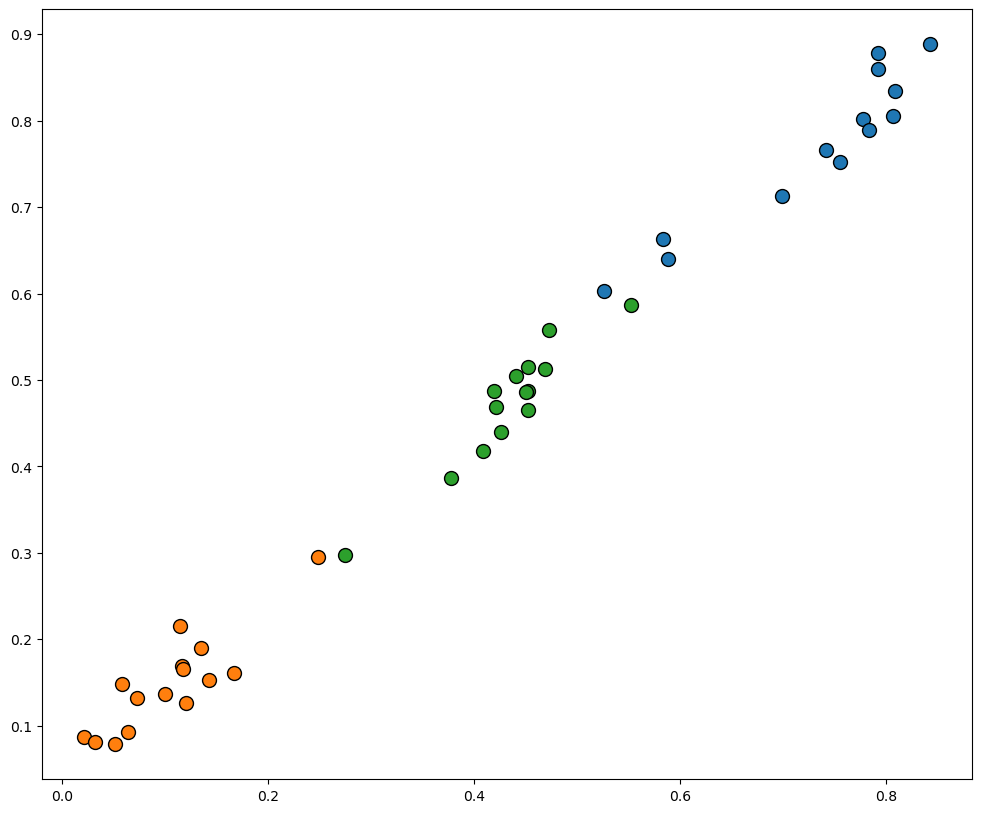

In [26]:
import matplotlib.pyplot as plt
plot_cluster(x_test, y_pred_KM)

## DBSCAN 

In [63]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GridSearchCV

# Настройка параметров для поиска
param_grid = {
    'eps': [0.1, 0.2, 0.3, 0.4, 0.5],
    'min_samples': [3, 4, 5, 6, 7]
}

# Определение функции для оценки
def silhouette_dbscan(X, eps, min_samples):
    model = DBSCAN(eps=eps, min_samples=min_samples)
    y_pred = model.fit_predict(X)
    if len(set(y_pred)) > 1:  # Проверяем, чтобы в модели были хотя бы два кластера
        return silhouette_score(X, y_pred)
    else:
        return -1  # если всего один кластер, возвращаем плохое значение

# Применение GridSearch
best_score = -1
best_params = None
for eps in param_grid['eps']:
    for min_samples in param_grid['min_samples']:
        score = silhouette_dbscan(x_train, eps, min_samples)
        if score > best_score:
            best_score = score
            best_params = {'eps': eps, 'min_samples': min_samples}

print(f"Лучшие параметры: {best_params}, лучший силуэтный коэффициент: {best_score:.4f}")

Лучшие параметры: {'eps': 0.2, 'min_samples': 5}, лучший силуэтный коэффициент: 0.2430


In [28]:
from sklearn.cluster import DBSCAN

model_DBSCAN = DBSCAN(eps=0.2, min_samples = 4)
y_pred_DBSCAN = model_DBSCAN.fit_predict(x_train)

In [29]:
sil_avg_db = silhouette_score(x_train, y_pred_DBSCAN)
print(f"Силуэтный коэффициент: {sil_avg_db:.2f}")
print('Относительная кластеризация')

Силуэтный коэффициент: 0.07
Относительная кластеризация


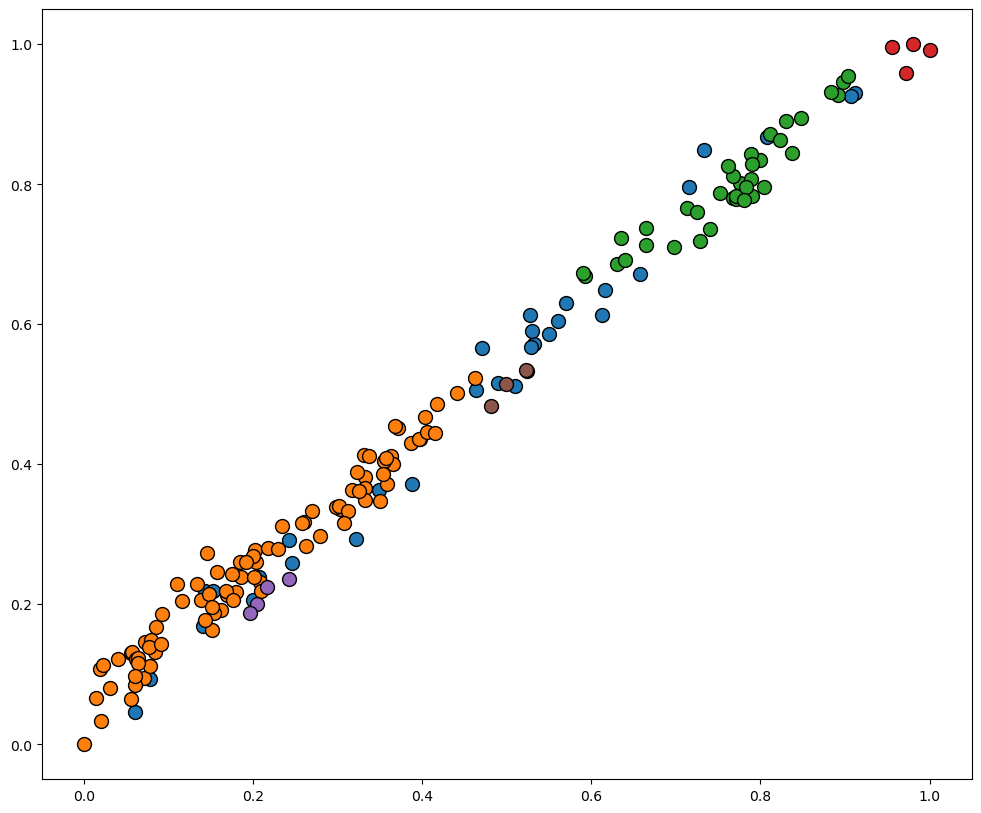

In [30]:
plot_cluster(x_train, y_pred_DBSCAN)

## Алгоритм Agglomerative Clustering

In [32]:
from sklearn.cluster import AgglomerativeClustering

model_AC = AgglomerativeClustering(n_clusters=3)
y_pred_AC = model_AC.fit_predict(x_train)

In [33]:
sil_avg_ac = silhouette_score(x_train, y_pred_AC)
print(f"Силуэтный коэффициент: {sil_avg_ac:.2f}")
print('Вполне удовлетворительная кластеризация')

Силуэтный коэффициент: 0.38
Вполне удовлетворительная кластеризация


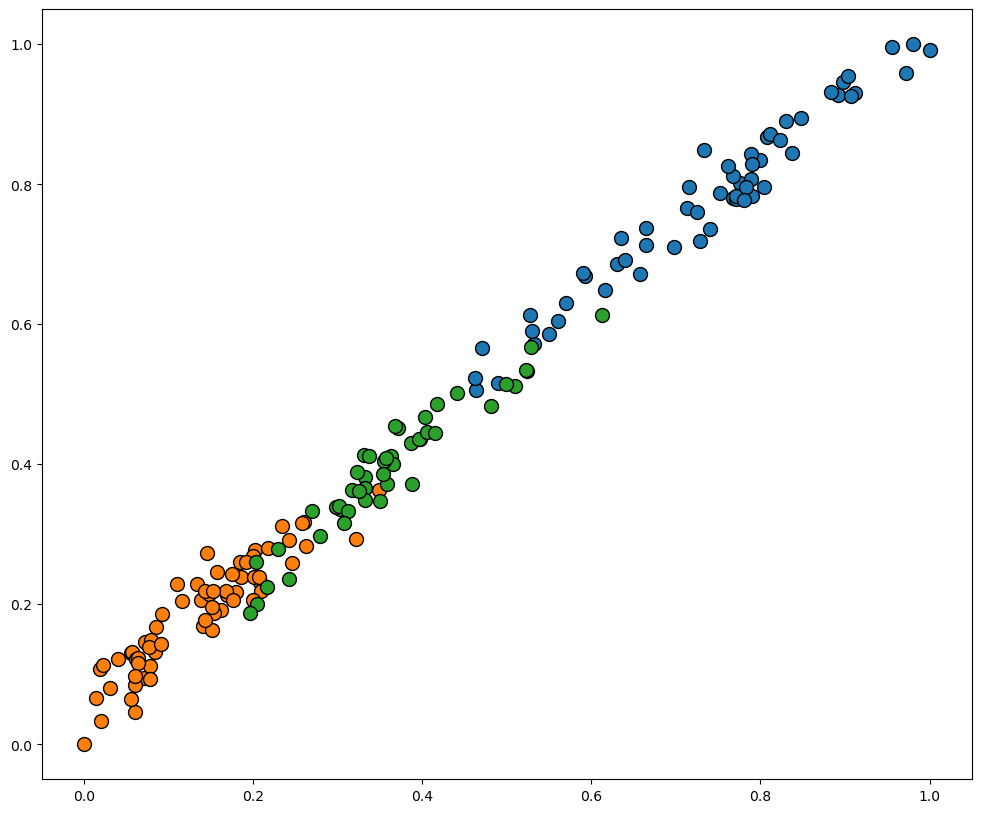

In [34]:
plot_cluster(x_train, y_pred_AC)

## Алгоритм Gaussian Mixture Model

In [36]:
from sklearn.mixture import GaussianMixture

model_GM = GaussianMixture(n_components=3)
model_GM.fit(x_train)
y_pred_GM = model_GM.predict(x_test)

In [37]:
sil_avg_gm = silhouette_score(x_test, y_pred_GM)
print(f"Cилуэтный коэффициент: {sil_avg_gm:.2f}")
print('Вполне удовлетворительная кластеризация')

Cилуэтный коэффициент: 0.42
Вполне удовлетворительная кластеризация


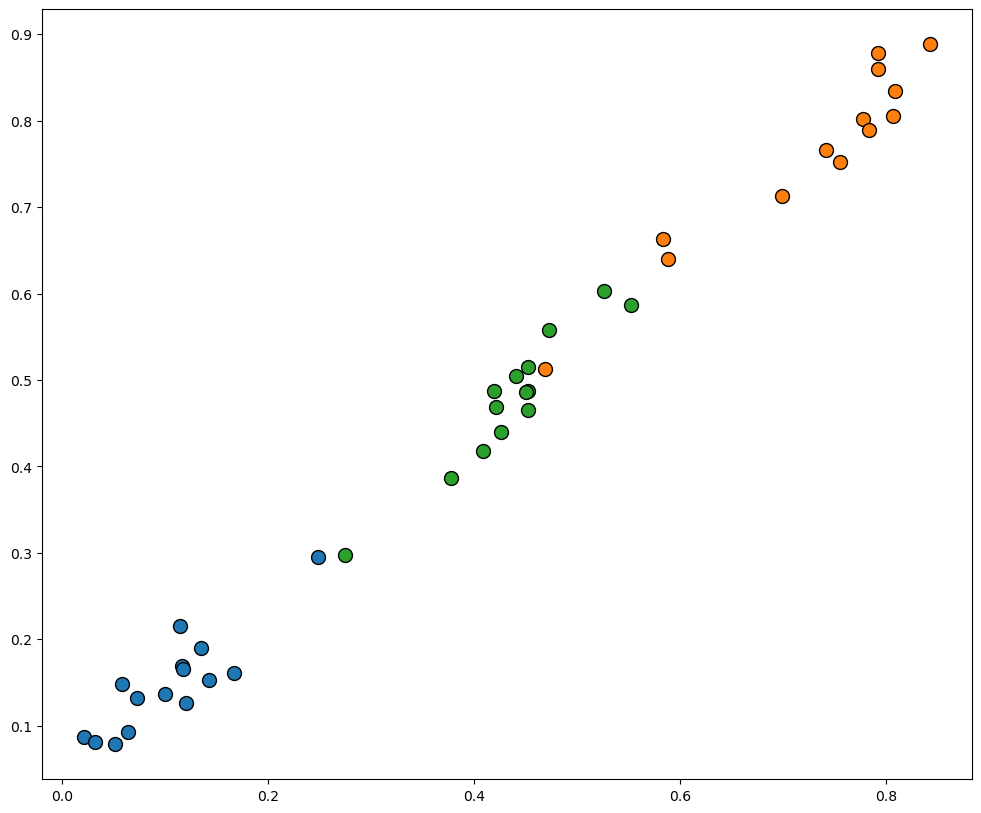

In [38]:
plot_cluster(x_test, y_pred_GM)